# 4.2. Modelo predictivo base

## Objetivo

Predecir la cantidad de conexiones de internet fijo
del siguiente trimestre por unidad territorial,
con la finalidad de apoyar el seguimiento de
variaciones relevantes en los registros de OSIPTEL.

## Metodología

- Aprendizaje supervisado.
- Problema de regresión.
- Granularidad: departamento / Callao por trimestre.
- Periodo de estudio: marzo de 2016 a marzo de 2026.
- Horizonte predictivo: un trimestre.
- Fuente de datos: Gold F1 territorial.
- Motor de procesamiento y modelado: Apache Spark MLlib.

Se utilizará un método de persistencia como referencia
y una regresión lineal como primer modelo entrenado.
La evaluación respetará el orden cronológico de los datos.

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window

from pyspark.ml.feature import VectorAssembler
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator

spark = (
    SparkSession.builder
    .appName("OSIPTEL_Modelo_Base")
    .master("local[2]")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("ERROR")

PROYECTO = next(
    p for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "run_pipeline.py").is_file()
    and (p / "notebooks").is_dir()
)

BASE = PROYECTO / "data" / "paquete_20261125_c5cc727"

RESULTADOS = PROYECTO / "results" / "modelo_base"
RESULTADOS.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid")

territorial = spark.read.parquet(
    (BASE / "f1_historico_territorial").as_uri()
)

panel = (
    territorial
    .filter(F.col("periodo").between("2016-03", "2026-03"))
    .groupBy("departamento", "periodo")
    .agg(
        F.sum("conexiones_fijas").alias("conexiones")
    )
    .orderBy("departamento", "periodo")
)

print("Observaciones del panel:", panel.count())

Observaciones del panel: 1025


In [3]:
ventana = (
    Window
    .partitionBy("departamento")
    .orderBy("periodo")
)

datos_modelo = (
    panel

    .withColumn(
        "conexiones_anterior",
        F.lag("conexiones", 1).over(ventana)
    )

    .withColumn(
        "conexiones_anio_anterior",
        F.lag("conexiones", 4).over(ventana)
    )

    .withColumn(
        "crecimiento_trimestral",
        F.col("conexiones") - F.col("conexiones_anterior")
    )

    .withColumn(
        "crecimiento_interanual",
        F.col("conexiones") - F.col("conexiones_anio_anterior")
    )

    .withColumn(
        "periodo_objetivo",
        F.lead("periodo", 1).over(ventana)
    )

    .withColumn(
        "conexiones_objetivo",
        F.lead("conexiones", 1).over(ventana)
    )

    .withColumn(
        "variacion_objetivo",
        F.col("conexiones_objetivo") - F.col("conexiones")
    )
)

features = [
    "conexiones",
    "crecimiento_trimestral",
    "crecimiento_interanual"
]

datos_supervisados = datos_modelo.dropna(
    subset=features + [
        "periodo_objetivo",
        "conexiones_objetivo",
        "variacion_objetivo"
    ]
)

print("Observaciones originales:", panel.count())

print(
    "Observaciones para modelado:",
    datos_supervisados.count()
)

display(
    datos_supervisados
    .filter(F.col("departamento") == "LA LIBERTAD")
    .orderBy("periodo")
    .limit(10)
    .toPandas()
)

Observaciones originales: 1025
Observaciones para modelado: 900


,departamento,periodo,conexiones,conexiones_anterior,conexiones_anio_anterior,crecimiento_trimestral,crecimiento_interanual,periodo_objetivo,conexiones_objetivo,variacion_objetivo
0,LA LIBERTAD,2017-03,116032,115474,107970,558,8062,2017-06,119011,2979
1,LA LIBERTAD,2017-06,119011,116032,113098,2979,5913,2017-09,124101,5090
2,LA LIBERTAD,2017-09,124101,119011,114144,5090,9957,2017-12,125337,1236
3,LA LIBERTAD,2017-12,125337,124101,115474,1236,9863,2018-03,126743,1406
4,LA LIBERTAD,2018-03,126743,125337,116032,1406,10711,2018-06,132803,6060
5,LA LIBERTAD,2018-06,132803,126743,119011,6060,13792,2018-09,136149,3346
6,LA LIBERTAD,2018-09,136149,132803,124101,3346,12048,2018-12,141249,5100
7,LA LIBERTAD,2018-12,141249,136149,125337,5100,15912,2019-03,118444,-22805
8,LA LIBERTAD,2019-03,118444,141249,126743,-22805,-8299,2019-06,130291,11847
9,LA LIBERTAD,2019-06,130291,118444,132803,11847,-2512,2019-09,130910,619


In [4]:
entrenamiento = datos_supervisados.filter(
    F.col("periodo_objetivo") <= "2023-12"
)

validacion = datos_supervisados.filter(
    F.col("periodo_objetivo").between("2024-03", "2024-12")
)

prueba = datos_supervisados.filter(
    F.col("periodo_objetivo").between("2025-03", "2026-03")
)

resumen = []

for nombre, df in [
    ("Entrenamiento", entrenamiento),
    ("Validacion", validacion),
    ("Prueba final", prueba)
]:

    info = df.agg(
        F.count("*").alias("observaciones"),
        F.min("periodo_objetivo").alias("desde"),
        F.max("periodo_objetivo").alias("hasta"),
        F.countDistinct("periodo_objetivo").alias("trimestres")
    ).first().asDict()

    info["conjunto"] = nombre
    resumen.append(info)

display(pd.DataFrame(resumen))

,observaciones,desde,hasta,trimestres,conjunto
0,675,2017-06,2023-12,27,Entrenamiento
1,100,2024-03,2024-12,4,Validacion
2,125,2025-03,2026-03,5,Prueba final


In [6]:
assembler = VectorAssembler(
    inputCols=features,
    outputCol="features"
)

train_ml = assembler.transform(entrenamiento)
val_ml = assembler.transform(validacion)

pred_persistencia = validacion.withColumn(
    "prediccion",
    F.col("conexiones").cast("double")
)

lr = LinearRegression(
    featuresCol="features",
    labelCol="variacion_objetivo",
    predictionCol="variacion_predicha",
    maxIter=100,
    regParam=0.0
)

modelo_lr = lr.fit(train_ml)

pred_lr = (
    modelo_lr.transform(val_ml)
    .withColumn(
        "prediccion",
        F.greatest(
            F.lit(0.0),
            F.col("conexiones") + F.col("variacion_predicha")
        )
    )
)

print("Modelo de regresion lineal entrenado")

display(
    pd.DataFrame({
        "Variable": features,
        "Coeficiente": modelo_lr.coefficients.toArray()
    })
)

print("Intercepto:", modelo_lr.intercept)

Modelo de regresion lineal entrenado


,Variable,Coeficiente
0,conexiones,0.014544
1,crecimiento_trimestral,-0.445319
2,crecimiento_interanual,0.110453


Intercepto: 543.9925946290591


In [7]:
def evaluar(nombre, df):

    mae = RegressionEvaluator(
        labelCol="conexiones_objetivo",
        predictionCol="prediccion",
        metricName="mae"
    ).evaluate(df)

    rmse = RegressionEvaluator(
        labelCol="conexiones_objetivo",
        predictionCol="prediccion",
        metricName="rmse"
    ).evaluate(df)

    r2 = RegressionEvaluator(
        labelCol="conexiones_objetivo",
        predictionCol="prediccion",
        metricName="r2"
    ).evaluate(df)

    valores = df.agg(
        F.sum(
            F.abs(
                F.col("conexiones_objetivo") - F.col("prediccion")
            )
        ).alias("error_total"),

        F.sum(
            F.col("conexiones_objetivo")
        ).alias("total_real")
    ).first()

    wape = (
        valores["error_total"] / valores["total_real"]
    ) * 100

    return {
        "Modelo": nombre,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2,
        "WAPE_pct": wape
    }

metricas = pd.DataFrame([
    evaluar("Persistencia", pred_persistencia),
    evaluar("Regresion lineal", pred_lr)
])

display(metricas.round(4))

metricas.to_csv(
    RESULTADOS / "metricas_validacion.csv",
    index=False
)

,Modelo,MAE,RMSE,R2,WAPE_pct
0,Persistencia,4602.3700,8858.5465,0.9995,2.9813
1,Regresion lineal,3011.0302,5238.7262,0.9998,1.9505


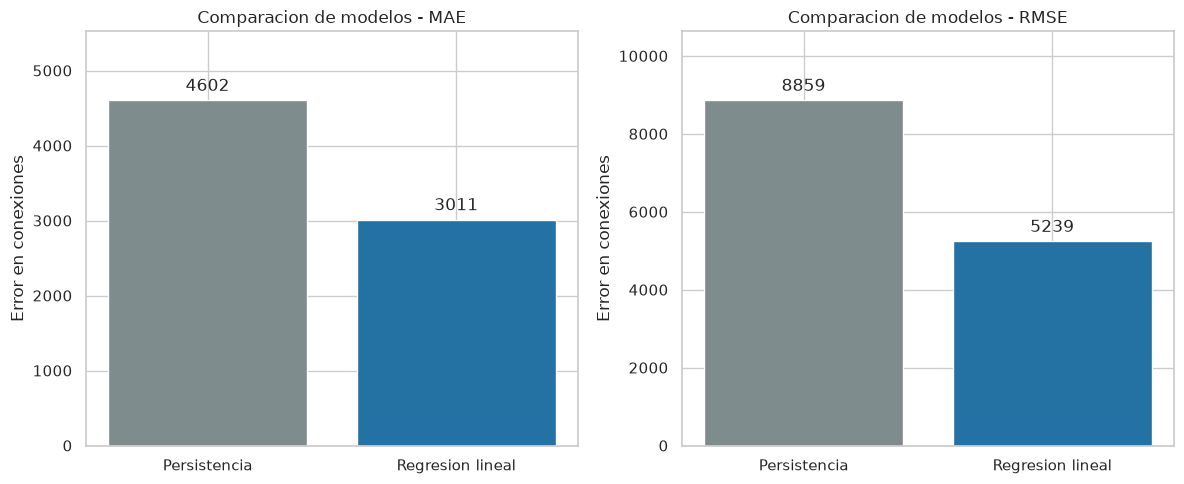

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

colores = ["#7F8C8D", "#2471A3"]

for ax, metrica in zip(axes, ["MAE", "RMSE"]):

    barras = ax.bar(
        metricas["Modelo"],
        metricas[metrica],
        color=colores
    )

    ax.bar_label(barras, fmt="%.0f", padding=4)
    ax.set_title(f"Comparacion de modelos - {metrica}")
    ax.set_ylabel("Error en conexiones")
    ax.set_ylim(0, metricas[metrica].max() * 1.2)

plt.tight_layout()

plt.savefig(
    RESULTADOS / "01_comparacion_modelos_base.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Interpretación de los resultados

La regresión lineal obtuvo un MAE de 3.011,03 conexiones, frente a las 4.602,37 del método de persistencia, representando una reducción del error promedio del 34,58 %.

Asimismo, el RMSE disminuyó un 40,86 %, lo que indica una reducción en la magnitud de los errores grandes durante el periodo de validación.

El WAPE disminuyó del 2,98 % al 1,95 %. Aunque ambos modelos presentan valores elevados de R², esta métrica no se considera suficiente para determinar su capacidad predictiva debido a las diferencias en el volumen de conexiones entre departamentos.

Los coeficientes obtenidos representan relaciones estadísticas entre las variables históricas y la variación esperada de conexiones, sin establecer relaciones causales.

Se establece la regresión lineal como modelo base entrenado y su MAE de 3.011,03 conexiones como línea base técnica de validación. En la siguiente etapa se evaluarán modelos no lineales para determinar si es posible reducir los errores de predicción.

Los resultados corresponden exclusivamente a los cuatro trimestres de 2024. El rendimiento sobre el conjunto de prueba de 2025 a marzo de 2026 todavía no ha sido evaluado.